In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
TICKETS_PATH = "../data/raw/support_tickets.csv"

tickets_df = pd.read_csv(TICKETS_PATH)

print("Dataset shape:", tickets_df.shape)

display(
    tickets_df[
        ["ticket_text", "ticket_category", "priority"]
    ].head()
)

Dataset shape: (10000, 15)


,ticket_text,ticket_category,priority
0,The lipstick I received in order #ORD5614226 s...,Product Issue,High
1,The shoe rack received in order #ORD8038374 ha...,Product Issue,High
2,I want to exchange my conditioner (order #ORD6...,Refund & Return,Low
3,My makeup brush set from order #ORD4823498 app...,Product Issue,High
4,Product listing for lipstick is completely mis...,Product Issue,Medium


In [3]:
print("Priority Distribution:")
display(
    tickets_df["priority"].value_counts()
)

print("\nPriority Percentage:")
display(
    tickets_df["priority"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Priority Distribution:


priority
High      4620
Medium    3657
Low       1723
Name: count, dtype: int64


Priority Percentage:


priority
High      46.20
Medium    36.57
Low       17.23
Name: proportion, dtype: float64

In [ ]:
# Cross-tab category vs priority
category_priority = pd.crosstab(
    tickets_df["ticket_category"],
    tickets_df["priority"]
)

display(category_priority)

priority,High,Low,Medium
ticket_category,,,
Account & Login,286,306,438
App & Website Issue,31,418,268
Delivery Issue,1009,165,776
Payment Issue,729,240,505
Product Issue,1110,177,661
Refund & Return,996,382,673
Seller & Product Listing,459,35,336


In [ ]:
# Priority vs sentiment
sentiment_priority = pd.crosstab(
    tickets_df["sentiment"],
    tickets_df["priority"]
)

display(sentiment_priority)

priority,High,Low,Medium
sentiment,,,
Negative,3077,0,0
Neutral,0,875,1857
Positive,0,848,0
Slightly Negative,0,0,1800
Very Negative,1543,0,0


In [ ]:
# Check duplicate ticket text
priority_df = tickets_df[
    ["ticket_text", "priority"]
].copy()

priority_df["clean_text"] = (
    priority_df["ticket_text"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

duplicate_count = priority_df[
    "clean_text"
].duplicated().sum()

print("Duplicate ticket texts:", duplicate_count)

Duplicate ticket texts: 1223


In [ ]:
# Remove duplicate texts
priority_unique = priority_df.drop_duplicates(
    subset=["clean_text"]
).copy()

print("Original records:", len(priority_df))
print("Unique ticket texts:", len(priority_unique))
print(
    "Removed duplicates:",
    len(priority_df) - len(priority_unique)
)

Original records: 10000
Unique ticket texts: 8777
Removed duplicates: 1223


In [ ]:
# Check priority distribution after deduplication
display(
    priority_unique["priority"].value_counts()
)

priority
High      4320
Medium    3081
Low       1376
Name: count, dtype: int64

In [9]:
X_priority = priority_unique["clean_text"]
y_priority = priority_unique["priority"]

print("Features:", X_priority.shape)
print("Target:", y_priority.shape)

print("\nPriority distribution:")
display(y_priority.value_counts())

Features: (8777,)
Target: (8777,)

Priority distribution:


priority
High      4320
Medium    3081
Low       1376
Name: count, dtype: int64

In [10]:
X_train_priority, X_test_priority, y_train_priority, y_test_priority = train_test_split(
    X_priority,
    y_priority,
    test_size=0.20,
    random_state=42,
    stratify=y_priority
)

print("Training samples:", len(X_train_priority))
print("Testing samples :", len(X_test_priority))

Training samples: 7021
Testing samples : 1756


In [11]:
priority_tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_priority_tfidf = priority_tfidf.fit_transform(
    X_train_priority
)

X_test_priority_tfidf = priority_tfidf.transform(
    X_test_priority
)

print(
    "Training TF-IDF shape:",
    X_train_priority_tfidf.shape
)

print(
    "Testing TF-IDF shape:",
    X_test_priority_tfidf.shape
)

Training TF-IDF shape: (7021, 3140)
Testing TF-IDF shape: (1756, 3140)


In [12]:
priority_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

priority_model.fit(
    X_train_priority_tfidf,
    y_train_priority
)

print("Priority model training completed.")

Priority model training completed.


In [13]:
y_pred_priority = priority_model.predict(
    X_test_priority_tfidf
)

print(
    "Predictions generated:",
    len(y_pred_priority)
)

Predictions generated: 1756


In [14]:
priority_accuracy = accuracy_score(
    y_test_priority,
    y_pred_priority
)

priority_precision = precision_score(
    y_test_priority,
    y_pred_priority,
    average="weighted"
)

priority_recall = recall_score(
    y_test_priority,
    y_pred_priority,
    average="weighted"
)

priority_f1 = f1_score(
    y_test_priority,
    y_pred_priority,
    average="weighted"
)

print("=" * 60)
print("PRIORITY MODEL PERFORMANCE")
print("=" * 60)

print(f"Accuracy : {priority_accuracy:.4f}")
print(f"Precision: {priority_precision:.4f}")
print(f"Recall   : {priority_recall:.4f}")
print(f"F1 Score : {priority_f1:.4f}")

PRIORITY MODEL PERFORMANCE
Accuracy : 0.9134
Precision: 0.9136
Recall   : 0.9134
F1 Score : 0.9119


In [15]:
print(
    classification_report(
        y_test_priority,
        y_pred_priority
    )
)

              precision    recall  f1-score   support

        High       0.91      0.96      0.93       864
         Low       0.92      0.75      0.83       275
      Medium       0.91      0.93      0.92       617

    accuracy                           0.91      1756
   macro avg       0.91      0.88      0.89      1756
weighted avg       0.91      0.91      0.91      1756



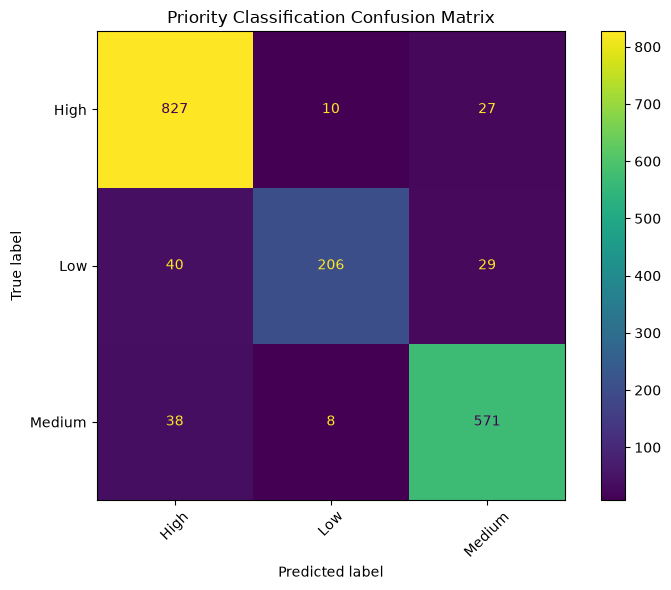

In [16]:
cm_priority = confusion_matrix(
    y_test_priority,
    y_pred_priority,
    labels=priority_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_priority,
    display_labels=priority_model.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("Priority Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
priority_enhanced = tickets_df[
    ["ticket_text", "ticket_category", "sentiment", "priority"]
].copy()

priority_enhanced["clean_text"] = (
    priority_enhanced["ticket_text"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

priority_enhanced = priority_enhanced.drop_duplicates(
    subset=["clean_text"]
).copy()

display(priority_enhanced.head())

print("Enhanced dataset:", priority_enhanced.shape)

,ticket_text,ticket_category,sentiment,priority,clean_text
0,The lipstick I received in order #ORD5614226 s...,Product Issue,Negative,High,the lipstick i received in order #ord5614226 s...
1,The shoe rack received in order #ORD8038374 ha...,Product Issue,Negative,High,the shoe rack received in order #ord8038374 ha...
2,I want to exchange my conditioner (order #ORD6...,Refund & Return,Positive,Low,i want to exchange my conditioner (order #ord6...
3,My makeup brush set from order #ORD4823498 app...,Product Issue,Very Negative,High,my makeup brush set from order #ord4823498 app...
4,Product listing for lipstick is completely mis...,Product Issue,Neutral,Medium,product listing for lipstick is completely mis...


Enhanced dataset: (8777, 5)


In [19]:
X_enhanced = priority_enhanced[
    ["clean_text", "ticket_category", "sentiment"]
]

y_enhanced = priority_enhanced["priority"]

X_train_enh, X_test_enh, y_train_enh, y_test_enh = train_test_split(
    X_enhanced,
    y_enhanced,
    test_size=0.20,
    random_state=42,
    stratify=y_enhanced
)

print("Training samples:", len(X_train_enh))
print("Testing samples :", len(X_test_enh))

Training samples: 7021
Testing samples : 1756


In [20]:
enhanced_tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_text = enhanced_tfidf.fit_transform(
    X_train_enh["clean_text"]
)

X_test_text = enhanced_tfidf.transform(
    X_test_enh["clean_text"]
)

print("Text TF-IDF training shape:", X_train_text.shape)
print("Text TF-IDF testing shape :", X_test_text.shape)

Text TF-IDF training shape: (7021, 3140)
Text TF-IDF testing shape : (1756, 3140)


In [21]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore"
)

X_train_cat_sent = encoder.fit_transform(
    X_train_enh[
        ["ticket_category", "sentiment"]
    ]
)

X_test_cat_sent = encoder.transform(
    X_test_enh[
        ["ticket_category", "sentiment"]
    ]
)

print(
    "Category + Sentiment training shape:",
    X_train_cat_sent.shape
)

print(
    "Category + Sentiment testing shape:",
    X_test_cat_sent.shape
)

Category + Sentiment training shape: (7021, 12)
Category + Sentiment testing shape: (1756, 12)


In [22]:
from scipy.sparse import hstack

X_train_enhanced = hstack([
    X_train_text,
    X_train_cat_sent
])

X_test_enhanced = hstack([
    X_test_text,
    X_test_cat_sent
])

print(
    "Final enhanced training shape:",
    X_train_enhanced.shape
)

print(
    "Final enhanced testing shape:",
    X_test_enhanced.shape
)

Final enhanced training shape: (7021, 3152)
Final enhanced testing shape: (1756, 3152)


In [23]:
enhanced_priority_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

enhanced_priority_model.fit(
    X_train_enhanced,
    y_train_enh
)

print("Enhanced priority model training completed.")

Enhanced priority model training completed.


In [24]:
y_pred_enhanced = enhanced_priority_model.predict(
    X_test_enhanced
)

print(
    "Enhanced predictions generated:",
    len(y_pred_enhanced)
)

Enhanced predictions generated: 1756


In [25]:
enh_accuracy = accuracy_score(
    y_test_enh,
    y_pred_enhanced
)

enh_precision = precision_score(
    y_test_enh,
    y_pred_enhanced,
    average="weighted"
)

enh_recall = recall_score(
    y_test_enh,
    y_pred_enhanced,
    average="weighted"
)

enh_f1 = f1_score(
    y_test_enh,
    y_pred_enhanced,
    average="weighted"
)

print("=" * 60)
print("ENHANCED PRIORITY MODEL PERFORMANCE")
print("=" * 60)

print(f"Accuracy : {enh_accuracy:.4f}")
print(f"Precision: {enh_precision:.4f}")
print(f"Recall   : {enh_recall:.4f}")
print(f"F1 Score : {enh_f1:.4f}")

ENHANCED PRIORITY MODEL PERFORMANCE
Accuracy : 0.9841
Precision: 0.9840
Recall   : 0.9841
F1 Score : 0.9840


In [26]:
print(
    classification_report(
        y_test_enh,
        y_pred_enhanced
    )
)

              precision    recall  f1-score   support

        High       1.00      1.00      1.00       864
         Low       0.96      0.94      0.95       275
      Medium       0.97      0.98      0.98       617

    accuracy                           0.98      1756
   macro avg       0.98      0.97      0.98      1756
weighted avg       0.98      0.98      0.98      1756

